# Stimulus image check

**This is a check of the stimuli, specified on 10 October 2026, after every registered result was known. No registration names it, and it changes no registered verdict. The comparison with the ratings in section 7 is description only. Every table this notebook writes says so in its last column, `analysis_status`, and each figure says so in two lines at its foot.**

Studies 2, 4 and 5 asked participants to rate a second work that the artist Alex made from a first artwork, at three levels of modification: None (the first work shown again unchanged), Slight (described in the registrations as colour and contrast adjustments; seven of the ten Slight versions also differ from their original in pixel size and in the ratio of width to height, as the table in section 2 shows, so they also crop or resize the picture) and Dramatic (substantial changes by hand). The design takes three properties of the images for granted, and no analysis has measured them.

1. The ten first artworks differ from one another.
2. Each artwork's Slight second work is closer to it than its Dramatic second work is.
3. Each second work, however much Alex changed it, is still closer to its own first artwork than to any of the other nine.

If the third failed, a Dramatic second work could stand nearer to another artwork than to the one it was made from, and a question about how far the second work moved from the first would rest on a pairing the pictures do not support. This notebook measures the distance between images in three ways and applies three checks, one for each property, with rules written in code before any distance is computed.

No person and no language model judges, labels or codes any image or any response. Two pretrained networks turn each image into a list of numbers and do nothing else, and the third measure counts colours.

**The images.** `extract_stimuli.py`, run once, took the 30 images out of the printout of the Study 5 survey and named each by its artwork and version, with the survey file as the authority; `stimuli/stimuli_manifest.csv` records how each was identified. The ten artworks are `1Figure` to `5Figure`, which show a human or humanoid figure, and `1NonFigure` to `5NonFigure`. Each has three versions: the original, the Slight second work and the Dramatic second work. The None second work is the original shown again, so it has no file of its own; section 2 confirms from the manifest that the survey showed the original's graphic there.

**Three measures of distance.**

- **DINOv2.** A pretrained network is a large function fitted beforehand to millions of other images, which turns an image into a list of numbers, the image's *embedding*. DINOv2 is a vision network that Meta trained without labels, by teaching it to give matching numbers to different views of the same photograph, so that its numbers describe the layout, shapes and content of an image. The version used is `facebook/dinov2-base` at revision `f9e44c814b77203eaa57a6bdbbd535f21ede1415`, a fixed snapshot of the model's files that cannot change later. The network cuts the image into small square patches and adds one extra slot, the class token, which gathers a summary of the whole image as the layers run. The embedding is the class token after the last layer and after the model's final normalisation, a step that rescales the numbers to a standard spread (the output the library calls `pooler_output`), 768 numbers.
- **CLIP.** CLIP is a vision network that OpenAI trained to match images with their captions, so its numbers reflect what a picture would be described as. The version used is `openai/clip-vit-base-patch32` at revision `3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268`. The embedding is the output of `get_image_features`, the 512 numbers the network compares with the numbers of a caption.
- **Colour.** No network. Each image is shrunk until its longer side is 512 pixels with the box filter, which makes each new pixel the average of the old pixels it covers. Each pixel is converted from sRGB, the standard colour space of screens and the web, with which Chrome tagged every stimulus image in the printout, to CIELAB, a colour space in which equal steps look roughly equally different to the eye. In CIELAB, L is lightness from 0 (black) to 100 (white), a runs from green (negative) to red (positive), and b runs from blue (negative) to yellow (positive). The conversion is the standard one for daylight white, called D65. A histogram counts how many pixels fall in each cell of a grid. Here the grid has 8 equal steps of L from 0 to 100, of a from -87 to 99 and of b from -108 to 95, 512 cells in all, and these ranges hold every sRGB colour. Each count is divided by the number of pixels, so the 512 shares sum to 1.

For the two networks, the distance between two images is 1 minus the cosine similarity of their embeddings, where the cosine similarity is the cosine of the angle between the two lists read as arrows: 1 when they point the same way, 0 when they are unrelated and negative when they point in opposite directions. The distance therefore runs from 0 to 2; two images that a network treats as unrelated lie near 1, and a few DINOv2 distances lie slightly above 1. For colour, the distance is the Hellinger distance between the two histograms, the square root of 1 minus the sum over cells of the square root of the product of the two shares. It is 0 when two images have the same mix of colours and 1 when they share no cell. Every distance is 0 for an image compared with itself and grows as two images differ.

**Two ways of feeding an image to a network.** The primary input is the whole image resized to 224 by 224 pixels with the bicubic filter, which makes each new pixel a smooth weighted average of the 16 nearest old pixels. Nothing is cropped, so no edit near an edge is lost, and an image that is not square is squeezed into the square. The robustness input is each network's standard preprocessing, the steps it was trained with, which resize the shorter side and keep the central 224 by 224 square (a centre crop): 256 pixels for DINOv2, 224 for CLIP. A centre crop drops the edges of an image that is not square. Every check is reported for both inputs, and section 6 says whether any verdict differs.

**Replicability.** The networks run in PyTorch, the library that does the networks' arithmetic, on the computer's main processor (CPU) only, with numbers stored as float32 (32-bit floating point, about seven significant digits). They run on one thread, one strand of computation, so the order in which numbers are added never changes, and with PyTorch's deterministic setting on, which stops the run at any operation whose result could vary from run to run. Each image goes through the network alone. No step draws a random number. Every file read and written is listed with its SHA-256 checksum, a 64-character fingerprint of a file's exact bytes, in the run manifest the notebook writes last.

---

# 0. Setup

The first cell sets the number of threads, keeps the Hugging Face libraries, which load the two networks, off the internet, so each network is read from the local cache, the folder where these libraries keep downloaded models, and stops them printing notices and progress bars. These settings must be in place before PyTorch and the Hugging Face libraries start. It finds this folder: the environment variable `IMAGE_CHECK_DIR`, a named setting the shell passes to a program, can name it, and otherwise it is the folder the notebook runs from. The pipeline folder is two levels up (`PIPELINE_DIR` can name it), and the project root, the folder that holds `Analysis` and `Stimuli`, two levels above that (`IMAGE_CHECK_PROJECT_ROOT` can name it). Every path the notebook prints is relative to the project root, and a file in the model cache is printed relative to the cache. A file outside the project root, which an environment variable can bring about, is printed relative to this folder or the pipeline folder, with that folder's label in angle brackets.

The cell then checks that the Python version and the version of every analysis package equal those in `requirements.txt`, and stops if one does not, since another version could give other numbers. A build label after a plus sign, such as `+cpu` in `2.5.1+cpu`, is ignored in the comparison and recorded in full. Setting `IMAGE_CHECK_ALLOW_OTHER_VERSIONS=1` lets the run go on and records the difference. Last, it deletes the previous run manifest, so a manifest on disk means the run reached its end.

In [1]:
import datetime
import hashlib
import importlib.metadata
import os
import platform
import sys
import warnings
from itertools import combinations

# One thread for every numerical library, set before PyTorch starts.
THREADS = 1
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[variable] = str(THREADS)
# The Hugging Face libraries read only the local cache.
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
# They print no notices or progress bars, which would otherwise be saved into the notebook.
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TQDM_DISABLE"] = "1"


def short_warning(message, category, filename, lineno, line=None):
    # A warning names the file it came from without the file's folder.
    return "%s: %s (%s, line %d)\n" % (category.__name__, message, os.path.basename(filename), lineno)


warnings.formatwarning = short_warning

import numpy as np
import pandas as pd
import scipy.stats
import torch
import matplotlib.pyplot as plt
from PIL import Image
import huggingface_hub
from huggingface_hub import hf_hub_download
import transformers
from transformers import AutoImageProcessor, CLIPModel, Dinov2Model

transformers.logging.set_verbosity_error()
torch.set_num_threads(THREADS)
try:
    torch.set_num_interop_threads(THREADS)
except RuntimeError:
    # PyTorch takes this setting once per session; a rerun of the cell keeps the first one.
    pass
torch.use_deterministic_algorithms(True)

STATUS = ("stimulus check; specified on 10 October 2026, after every registered result was known; "
          "no registration names it; changes no registered verdict; the ratings comparison is description only")

# This folder, the pipeline folder and the project root.
HERE = os.path.abspath(os.environ.get("IMAGE_CHECK_DIR") or os.getcwd())
if not os.path.exists(os.path.join(HERE, "stimuli", "stimuli_manifest.csv")):
    raise FileNotFoundError("Could not find the image_check folder. Run the notebook from its own folder "
                            "or set IMAGE_CHECK_DIR to that folder.")
PIPELINE_DIR = os.path.abspath(os.environ.get("PIPELINE_DIR") or os.path.join(HERE, os.pardir, os.pardir))


def find_project_root():
    # The project root holds Analysis, and Analysis holds the pipeline folder.
    # In a copy laid out differently, the pipeline folder serves as the root.
    named = os.environ.get("IMAGE_CHECK_PROJECT_ROOT")
    if named:
        return os.path.abspath(named)
    analysis = os.path.dirname(PIPELINE_DIR)
    return os.path.dirname(analysis) if os.path.basename(analysis) == "Analysis" else PIPELINE_DIR


PROJECT_ROOT = find_project_root()
HF_CACHE = os.path.abspath(huggingface_hub.constants.HF_HUB_CACHE)
STIMULI_DIR = os.path.join(HERE, "stimuli")
TABLES_DIR = os.path.join(HERE, "tables")
FIGURES_DIR = os.path.join(HERE, "figures")
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)


def show(path):
    """A path for printing: relative to the model cache, the project root or a labelled folder."""
    path = os.path.abspath(path)
    for base, label in ((HF_CACHE, "<Hugging Face cache>"), (PROJECT_ROOT, None), (HERE, "<image_check>"),
                        (PIPELINE_DIR, "<pipeline>")):
        rel = os.path.relpath(path, base)
        if not rel.startswith(os.pardir):
            if not label:
                return rel
            return label if rel == os.curdir else os.path.join(label, rel)
    return os.path.join("<outside the project>", os.path.basename(path))


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


# The Python version and the analysis packages must equal those in requirements.txt.
REQUIREMENTS = os.path.join(HERE, "requirements.txt")
pinned = {}
with open(REQUIREMENTS) as handle:
    for line in handle:
        # A line holds a name, ==, a version and, after a semicolon, an optional platform condition.
        line = line.split("#")[0].split(";")[0].strip()
        if "==" in line:
            name, version = line.split("==")
            pinned[name.strip().lower()] = version.strip()
ANALYSIS_PACKAGES = ["torch", "torchvision", "transformers", "tokenizers", "safetensors", "huggingface_hub",
                     "pillow", "numpy", "pandas", "scipy", "matplotlib"]
installed = {p: importlib.metadata.version(p) for p in ANALYSIS_PACKAGES}


def release(version):
    # The version without a build label such as +cpu.
    return version.split("+")[0]


differences = ["%s %s (requirements.txt: %s)" % (p, installed[p], pinned[p])
               for p in ANALYSIS_PACKAGES if release(installed[p]) != pinned[p]]
if sys.version_info[:2] != (3, 12):
    differences.append("Python %s (the run used 3.12)" % platform.python_version())
ALLOW_OTHER = os.environ.get("IMAGE_CHECK_ALLOW_OTHER_VERSIONS") == "1"
if differences and not ALLOW_OTHER:
    raise RuntimeError("These versions differ from requirements.txt: " + "; ".join(differences)
                       + ". Install the pinned versions, or set IMAGE_CHECK_ALLOW_OTHER_VERSIONS=1 to go on.")

# The previous run manifest is deleted now and the new one is written last.
MANIFEST_PATH = os.path.join(TABLES_DIR, "image_check_run_manifest.csv")
if os.path.exists(MANIFEST_PATH):
    os.remove(MANIFEST_PATH)

RUN = dict(inputs=[], models=[], outputs=[])


def record(role, path):
    RUN[role].append(path)


def write_table(frame, name):
    """Writes a table to tables/ with analysis_status as its last column."""
    path = os.path.join(TABLES_DIR, name)
    if os.path.exists(path):
        os.remove(path)
    frame = frame.copy()
    frame["analysis_status"] = STATUS
    frame.to_csv(path, index=False, float_format="%.6f", lineterminator="\n")
    record("outputs", path)
    return path


print("This folder:", show(HERE))
print("Python", platform.python_version(), "| PyTorch", torch.__version__, "| threads", torch.get_num_threads(),
      "| deterministic", torch.are_deterministic_algorithms_enabled())
print("Versions differing from requirements.txt:", "; ".join(differences) if differences else "none")

This folder: Analysis/R Analysis Pipeline/Cross-study/image_check
Python 3.12.3 | PyTorch 2.5.1 | threads 1 | deterministic True
Versions differing from requirements.txt: none


---

# 1. The rules, fixed before any distance is computed

The three checks are written here as code, before the next sections compute a single distance. Each function takes a lookup `d(a, b)` that returns the distance between two image files on one measure.

- **Check 1, distinct artworks.** On a measure, the 45 distances among the ten originals are computed, and each original's nearest other original is found. The check passes when the smallest distance between two different originals is larger than the largest distance between any original and its own Slight version: the least different pair of artworks must still be farther apart than the most changed Slight edit is from its own original.
- **Check 2, ordered steps.** The None second work must be the original's graphic, with identical pixels and a distance of 0, which section 2 confirms. On each measure, for each of the ten artworks, the distance from the original to its Slight version must be smaller than the distance to its Dramatic version. The count out of 10 is reported, with every artwork that fails; the check passes on a measure when the count is 10.
- **Check 3, edits stay tied to their own original.** For each of the 20 edited images, the ten originals are ranked by their distance to it, 1 being the closest. An edited image passes when its own original ranks 1 with no other original at the same distance. The count out of 20 is reported, with every image that fails; the check passes on a measure when the count is 20.

In [2]:
ARTWORKS = ["%dFigure" % k for k in range(1, 6)] + ["%dNonFigure" % k for k in range(1, 6)]
VERSIONS = ["original", "Slight", "Dramatic"]


def check1_distinct(d, files):
    """Check 1: the closest two originals are farther apart than any original is from its own Slight version."""
    between = {(a, b): d(files[(a, "original")], files[(b, "original")]) for a, b in combinations(ARTWORKS, 2)}
    own_slight = {a: d(files[(a, "original")], files[(a, "Slight")]) for a in ARTWORKS}
    closest_pair = min(between, key=between.get)
    farthest_slight = max(own_slight, key=own_slight.get)
    rows = []
    for a in ARTWORKS:
        others = {b: between[tuple(sorted((a, b), key=ARTWORKS.index))] for b in ARTWORKS if b != a}
        nearest = min(others, key=others.get)
        rows.append(dict(artwork=a, nearest_other_original=nearest, nearest_other_distance=others[nearest],
                         own_slight_distance=own_slight[a]))
    summary = dict(smallest_between_originals=between[closest_pair],
                   smallest_between_pair="%s and %s" % closest_pair,
                   largest_between_originals=max(between.values()),
                   largest_own_slight=own_slight[farthest_slight], largest_own_slight_artwork=farthest_slight,
                   margin=between[closest_pair] - own_slight[farthest_slight],
                   check1_passes=bool(between[closest_pair] > own_slight[farthest_slight]))
    return rows, summary, between


def check2_steps(d, files):
    """Check 2: for each artwork, the Slight version is closer to the original than the Dramatic version is."""
    rows = []
    for a in ARTWORKS:
        slight = d(files[(a, "original")], files[(a, "Slight")])
        dramatic = d(files[(a, "original")], files[(a, "Dramatic")])
        rows.append(dict(artwork=a, slight_distance=slight, dramatic_distance=dramatic,
                         slight_below_dramatic=bool(slight < dramatic), slight_to_dramatic_ratio=slight / dramatic))
    count = sum(r["slight_below_dramatic"] for r in rows)
    summary = dict(count_slight_below_dramatic=count, check2_passes=bool(count == len(ARTWORKS)),
                   failing_artworks="; ".join(r["artwork"] for r in rows if not r["slight_below_dramatic"]))
    return rows, summary


def check3_ties(d, files):
    """Check 3: each edited image's own original is the closest of the ten originals, with no tie."""
    rows = []
    for a in ARTWORKS:
        for version in ("Slight", "Dramatic"):
            to_originals = {b: d(files[(a, version)], files[(b, "original")]) for b in ARTWORKS}
            own = to_originals[a]
            others = {b: v for b, v in to_originals.items() if b != a}
            nearest_other = min(others, key=others.get)
            rank = 1 + sum(v < own for v in others.values())
            ties = sum(v == own for v in others.values())
            rows.append(dict(artwork=a, version=version, own_original_distance=own, own_original_rank=rank,
                             originals_tied_with_own=ties, nearest_other_original=nearest_other,
                             nearest_other_distance=others[nearest_other],
                             margin=others[nearest_other] - own, passes=bool(rank == 1 and ties == 0)))
    count = sum(r["passes"] for r in rows)
    summary = dict(count_own_original_first=count, check3_passes=bool(count == len(rows)),
                   failing_images="; ".join("%s %s" % (r["artwork"], r["version"]) for r in rows if not r["passes"]))
    return rows, summary

---

# 2. The inputs and their checks

The notebook reads four kinds of file.

- **The 30 stimulus images** in `stimuli/`. They are kept in the repository with the code. If one is missing, the notebook stops and names it. Each must have the SHA-256 checksum the manifest records, and must decode to the pixels the manifest records: the checksum of its width, height and decoded red, green and blue values, which Pillow 10.3.0, the image library pinned in `requirements.txt`, produces from the file.
- **The extraction record**, `stimuli/stimuli_manifest.csv`, `stimuli/extraction_checks.csv` and `stimuli/extraction_run_manifest.csv`. Every required check of the extraction must have passed. Every file the extraction wrote must still have the checksum its run manifest records, and that manifest also gives the checksums of the printout and the survey files the extraction read. For each original, the manifest must record that the None second work showed the original's graphic ID and decoded to the original's pixels.
- **The ratings**, the long data files of Studies 2, 4 and 5 (`Study N/studyN_long_with_text.csv`), one row per participant, item and rating question. Each must have the checksum listed in its own study's run manifest (`Study N/tables/studyN_quant_run_manifest.csv`), which only that study's real run writes, and the column `label_mode` must say `real` on every row. The files are read with every value as text and with `keep_default_na=False`, because pandas, the Python library for tables, otherwise reads the level `None` as a missing value. Only five-point items are used, as each study's primary analysis does: the two six-point transformativeness items about `1NonFigure`, at None and at Slight, are left out.
- **The link from rating to image.** The manifest lists, for each image, the rating items asked about it: for an edited image, the items of the block that showed it as the second work, and for an original, the items of the None block. Every five-point item must map to one image, and its image and modification columns must agree with that map.

In [3]:
CHECKS = []


def check(name, expected, observed):
    """Records a check and stops the run if it fails."""
    passed = expected == observed
    CHECKS.append(dict(check=name, expected=str(expected), observed=str(observed), passed=passed))
    if not passed:
        raise AssertionError("%s: expected %s, observed %s." % (name, expected, observed))


def pixels_sha256(image):
    # The checksum covers the width, the height and every decoded value.
    array = np.asarray(image.convert("RGB"), dtype=np.uint8)
    header = ("%dx%dx3;" % (array.shape[1], array.shape[0])).encode()
    return hashlib.sha256(header + np.ascontiguousarray(array).tobytes()).hexdigest()


# The extraction record.
manifest_path = os.path.join(STIMULI_DIR, "stimuli_manifest.csv")
checks_path = os.path.join(STIMULI_DIR, "extraction_checks.csv")
extraction_run_path = os.path.join(STIMULI_DIR, "extraction_run_manifest.csv")
for path in (manifest_path, checks_path, extraction_run_path, REQUIREMENTS):
    record("inputs", path)
stimuli = pd.read_csv(manifest_path, dtype=str, keep_default_na=False)
extraction = pd.read_csv(checks_path, dtype=str, keep_default_na=False)
extraction_run = pd.read_csv(extraction_run_path, dtype=str, keep_default_na=False)

# Every image the manifest lists must be in stimuli/ before any is read.
missing = [name for name in stimuli["file"] if not os.path.exists(os.path.join(STIMULI_DIR, name))]
if missing:
    what = ("1 of the 30 stimulus images is" if len(missing) == 1
            else "%d of the 30 stimulus images are" % len(missing))
    raise FileNotFoundError("%s not in stimuli/: %s%s. The 30 images are part of the repository; restore them "
                            "from it, or make them again from the printout (README, step 5), and run the "
                            "notebook again." % (what, missing[0], "" if len(missing) == 1 else " and others"))
check("Required extraction checks that failed", 0,
      int(((extraction["required"] == "True") & (extraction["pass"] != "True")).sum()))

# Each file the extraction wrote has the checksum its run manifest records.
written = extraction_run[extraction_run["role"] == "output"]
check("Files the extraction wrote", 32, len(written))
for row in written.itertuples():
    name = os.path.basename(row.file)
    check("%s has the checksum in the extraction run manifest" % name, row.sha256,
          sha256_file(os.path.join(STIMULI_DIR, name)))
check("Stimulus images in the manifest", 30, len(stimuli))
check("Artworks and versions in the manifest", sorted((a, v) for a in ARTWORKS for v in VERSIONS),
      sorted(zip(stimuli["artwork"], stimuli["version"])))

# Each image file against its checksums.
IMAGES, FILES = {}, {}
for row in stimuli.itertuples():
    path = os.path.join(STIMULI_DIR, row.file)
    record("inputs", path)
    check("%s file checksum" % row.file, row.file_sha256, sha256_file(path))
    with Image.open(path) as opened:
        image = opened.convert("RGB")
    check("%s decoded pixel checksum" % row.file, row.pixels_sha256, pixels_sha256(image))
    check("%s size" % row.file, (int(row.pixel_width), int(row.pixel_height)), image.size)
    IMAGES[row.file] = image
    FILES[(row.artwork, row.version)] = row.file

# The None second work is the original.
for row in stimuli[stimuli["version"] == "original"].itertuples():
    check("%s None second work has the original's graphic ID" % row.artwork, row.survey_graphic_id,
          row.none_graphic_id)
    check("%s None second work decodes to the original's pixels" % row.artwork, row.pixels_sha256,
          row.none_pixels_sha256)

print("Stimulus images checked:", len(IMAGES))
print("Extraction checks on record:", len(extraction), "| failed:",
      int((extraction["pass"] == "False").sum()))
print("Inputs of the extraction, from its run manifest:")
print(extraction_run[extraction_run["role"] == "input"][["what", "file", "sha256"]].to_string(index=False))

Stimulus images checked: 30
Extraction checks on record: 538 | failed: 0
Inputs of the extraction, from its run manifest:
                      what                                                                             file                                                           sha256
                  printout                                            Stimuli/Qualtrics Survey Software.pdf 373814afe3399f6f03aa848baaa43231a49aab9bb613084ddd46e8a5717dca28
      survey file, Study 1 Analysis/R Analysis Pipeline/Exported Studies/Final_-_AI_Copyright_-_Study_1.qsf 08c059c2307bb284d180b783f926c3c74b91dec99af7eff002e5f1c700b1d1cd
      survey file, Study 2 Analysis/R Analysis Pipeline/Exported Studies/Final_-_AI_Copyright_-_Study_2.qsf cc6dc3db5d006a7143a7b346e3afedb3f0d0027bf7da1e538ef1b1d8a04bd224
      survey file, Study 3 Analysis/R Analysis Pipeline/Exported Studies/Final_-_AI_Copyright_-_Study_3.qsf 890bdf8aee31ff8144d337bf6d89471457094bf2acf58eb7326f67c021420df2
      survey 

In [4]:
# The ratings of Studies 2, 4 and 5, each with its arm (AI or Human) and image column.
STUDIES = {
    "Study 2": dict(arm="source", image="image", rows=20659, five_point=20659, people=235),
    "Study 4": dict(arm="label", image="source", rows=6318, five_point=6178, people=117),
    "Study 5": dict(arm="source", image="image", rows=12042, five_point=11768, people=223),
}
DIMENSIONS = {"Trans": "transformativeness", "Ess": "essence_change", "Creat": "creativity"}
LEVEL_OF_VERSION = {"original": "None", "Slight": "Slight", "Dramatic": "Dramatic"}

# Each rating item names the image it asks about, through the manifest.
ITEM_TO_FILE = {}
for row in stimuli.itertuples():
    for item in row.rated_item_tags.split("; "):
        ITEM_TO_FILE[item] = row.file
FILE_INFO = stimuli.set_index("file")

frames = []
for study, spec in STUDIES.items():
    number = study.split()[1]
    folder = os.path.join(PIPELINE_DIR, study)
    long_path = os.path.join(folder, "study%s_long_with_text.csv" % number)
    run_manifest = os.path.join(folder, "tables", "study%s_quant_run_manifest.csv" % number)
    record("inputs", long_path)
    record("inputs", run_manifest)
    listed = pd.read_csv(run_manifest, dtype=str, keep_default_na=False)
    listed = listed.loc[listed["file"] == "study%s_long_with_text.csv" % number, "sha256"].tolist()
    check("%s long data file has the checksum in its run manifest" % study, listed, [sha256_file(long_path)])

    raw = pd.read_csv(long_path, dtype=str, keep_default_na=False)
    check("%s label_mode says real on every row" % study, ["real"], sorted(raw["label_mode"].unique()))
    check("%s rows and participants" % study, (spec["rows"], spec["people"]), (len(raw), raw["id"].nunique()))
    five = raw[raw["k_points"] == "5"]
    check("%s five-point ratings" % study, spec["five_point"], len(five))
    check("%s arms" % study, ["AI", "Human"], sorted(five[spec["arm"]].unique()))

    frame = pd.DataFrame({"study": study, "id": five["id"], "arm": five[spec["arm"]], "item": five["item"],
                          "image": five[spec["image"]], "modification": five["modification"],
                          "dimension": five["dimension"], "rating": five["rating"].astype(float)})
    frame["file"] = frame["item"].map(ITEM_TO_FILE)
    check("%s five-point items that map to no image" % study, 0, int(frame["file"].isna().sum()))
    mapped = FILE_INFO.loc[frame["file"]]
    check("%s image column agrees with the item's image" % study, True,
          bool((mapped["artwork"].values == frame["image"].values).all()))
    check("%s modification column agrees with the item's level" % study, True,
          bool((mapped["rated_as_level"].values == frame["modification"].values).all()))
    check("%s dimension column agrees with the item's question" % study, True,
          bool((frame["item"].str.extract(r"(Trans|Ess|Creat)$")[0].map(DIMENSIONS) == frame["dimension"]).all()))
    frames.append(frame)
ratings = pd.concat(frames, ignore_index=True)

print("Checks passed so far: %d of %d. Sections 3 to 6 add their own, and section 9 writes them all."
      % (sum(c["passed"] for c in CHECKS), len(CHECKS)))
print(ratings.groupby("study").agg(ratings=("rating", "size"), participants=("id", "nunique")).to_string())

Checks passed so far: 173 of 173. Sections 3 to 6 add their own, and section 9 writes them all.
         ratings  participants
study                         
Study 2    20659           235
Study 4     6178           117
Study 5    11768           223


In [5]:
# The manifest fields this notebook uses.
STIMULUS_COLUMNS = ["file", "artwork", "image_kind", "version", "rated_as_level", "survey_graphic_id",
                    "rated_item_tags", "printout_pages", "pixel_width", "pixel_height", "stored_as",
                    "colour_profile", "signals_agreeing", "file_sha256", "pixels_sha256", "none_graphic_id",
                    "none_pixels_sha256"]
write_table(stimuli[STIMULUS_COLUMNS], "image_check_stimuli.csv")
print(stimuli[["file", "survey_graphic_id", "printout_pages", "pixel_width", "pixel_height",
               "signals_agreeing"]].to_string(index=False))

                   file  survey_graphic_id     printout_pages pixel_width pixel_height                                                   signals_agreeing
   1Figure_original.png IM_bOzN9fgiJO3ptLU     4; 5; 6; 8; 11        1024         1024 printout text and survey order; sharing pattern; stated pixel size
     1Figure_slight.png IM_4IwodriFx62n9Rk                  9        1024         1024 printout text and survey order; sharing pattern; stated pixel size
   1Figure_dramatic.jpg IM_bO3ekOr5r7la3Bk                 12        1024         1020 printout text and survey order; sharing pattern; stated pixel size
   2Figure_original.png IM_eWdgkf3hxs7b2JM 15; 16; 17; 19; 22        1024         1024 printout text and survey order; sharing pattern; stated pixel size
     2Figure_slight.png IM_ekyXascckzWqseO                 20         995          949 printout text and survey order; sharing pattern; stated pixel size
   2Figure_dramatic.jpg IM_4GdGR6Tn8gjPh0q                 23        3072   

---

# 3. The two networks

Each network is read from the local Hugging Face cache at its pinned revision, and only the files named here are read: the model's settings (`config.json`), its preprocessing settings (`preprocessor_config.json`) and its weights, the fitted numbers that define it. DINOv2's weights are in the `safetensors` format, a file of numbers that cannot run code when loaded, and `use_safetensors=True` makes sure no other weight file is read. CLIP's weights at the pinned revision exist only as `pytorch_model.bin`, which the library opens with PyTorch's restricted loader for files of weights. If a file is missing, the cell stops and names the one command in `README.md` that fetches both networks. Each file read must have the SHA-256 checksum written below, the one recorded when the networks were first fetched (the weight file of DINOv2 has the checksum its repository lists), so a damaged or altered copy in the cache stops the run. Loading must leave no weight of the model unfilled and no weight in the file unused, and each network must sit on the CPU with its weights in float32.

In [6]:
MODELS = {
    "DINOv2": dict(repo="facebook/dinov2-base", revision="f9e44c814b77203eaa57a6bdbbd535f21ede1415",
                   weights="model.safetensors", loader=Dinov2Model, use_safetensors=True,
                   embedding="pooler_output: the class token after the final layer normalisation",
                   sha256={"config.json": "f7ff4cfa73d2f70647dbf6950541ad25d73082d54c2e7e9bded160c7656b2a70",
                           "preprocessor_config.json":
                               "14e780d86fa1861f8751f868d7f45425b5feb55c38ca26f152ca5097ab30f828",
                           "model.safetensors": "d73036b56966966d07975d696bde331762f37297e2f095de8cea0040c3aa0841"}),
    "CLIP": dict(repo="openai/clip-vit-base-patch32", revision="3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268",
                 weights="pytorch_model.bin", loader=CLIPModel, use_safetensors=False,
                 embedding="get_image_features: the image embedding in the space CLIP shares with captions",
                 sha256={"config.json": "b575ef3c36f2a057fa19e221650105052d61cc9c1a972ec15019c6261ec98770",
                         "preprocessor_config.json":
                             "910e70b3956ac9879ebc90b22fb3bc8a75b6a0677814500101a4c072bd7857bd",
                         "pytorch_model.bin": "a63082132ba4f97a80bea76823f544493bffa8082296d62d71581a4feff1576f"}),
}
NETWORK, PROCESSOR, MODEL_ROWS = {}, {}, []
for name, spec in MODELS.items():
    paths = {}
    for filename in ("config.json", "preprocessor_config.json", spec["weights"]):
        try:
            paths[filename] = hf_hub_download(spec["repo"], filename, revision=spec["revision"],
                                              local_files_only=True)
        except Exception:
            # The message names the missing network; the library's own error, which names local folders, is dropped.
            raise FileNotFoundError("%s at revision %s is not in the local Hugging Face cache. Fetch the two "
                                    "networks once with the command in README.md, section 'How to run it from "
                                    "a fresh copy'." % (spec["repo"], spec["revision"])) from None
        check("%s %s checksum" % (name, filename), spec["sha256"][filename], sha256_file(paths[filename]))
        record("models", paths[filename])
    folder = os.path.dirname(paths["config.json"])
    model, loading = spec["loader"].from_pretrained(folder, use_safetensors=spec["use_safetensors"],
                                                    torch_dtype=torch.float32, output_loading_info=True)
    check("%s weights left unfilled or unused when loaded" % name, 0,
          sum(len(loading[k]) for k in ("missing_keys", "unexpected_keys", "mismatched_keys")))
    model.eval()
    # Where the weights sit and how they are stored, as observed on the loaded network.
    observed_device = sorted({p.device.type for p in model.parameters()})
    observed_dtype = sorted({str(p.dtype).replace("torch.", "") for p in model.parameters()})
    check("%s weights on the CPU" % name, ["cpu"], observed_device)
    check("%s weights in float32" % name, ["float32"], observed_dtype)
    NETWORK[name] = model
    PROCESSOR[name] = AutoImageProcessor.from_pretrained(folder)
    size = model.config.hidden_size if name == "DINOv2" else model.config.projection_dim
    MODEL_ROWS.append(dict(
        measure=name, repository=spec["repo"], revision=spec["revision"], weight_file=spec["weights"],
        weight_bytes=os.path.getsize(paths[spec["weights"]]), weight_sha256=sha256_file(paths[spec["weights"]]),
        config_sha256=sha256_file(paths["config.json"]),
        preprocessor_config_sha256=sha256_file(paths["preprocessor_config.json"]),
        processor_class=type(PROCESSOR[name]).__name__, embedding=spec["embedding"], embedding_size=size,
        primary_preprocessing="whole image resized to 224 x 224 pixels with the bicubic filter, no crop",
        robustness_preprocessing=("standard: shorter side resized to %s pixels with the bicubic filter, then the "
                                  "central 224 x 224 square" % (256 if name == "DINOv2" else 224)),
        distance="1 minus the cosine similarity of two embeddings", device="; ".join(observed_device),
        dtype="; ".join(observed_dtype), threads=THREADS))
MODEL_ROWS.append(dict(
    measure="colour", repository="none: no network", revision="", weight_file="", weight_bytes="",
    weight_sha256="", config_sha256="", preprocessor_config_sha256="", processor_class="",
    embedding="normalised 8 x 8 x 8 histogram of CIELAB colours (D65)", embedding_size=512,
    primary_preprocessing="longer side resized to 512 pixels with the box filter",
    robustness_preprocessing="", distance="Hellinger distance between two histograms", device="cpu",
    dtype="float64", threads=THREADS))
models_table = pd.DataFrame(MODEL_ROWS)
print(models_table[["measure", "repository", "revision", "weight_file", "weight_sha256", "embedding_size",
                    "processor_class"]].to_string(index=False))

measure                   repository                                 revision       weight_file                                                    weight_sha256  embedding_size    processor_class
 DINOv2         facebook/dinov2-base f9e44c814b77203eaa57a6bdbbd535f21ede1415 model.safetensors d73036b56966966d07975d696bde331762f37297e2f095de8cea0040c3aa0841             768  BitImageProcessor
   CLIP openai/clip-vit-base-patch32 3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268 pytorch_model.bin a63082132ba4f97a80bea76823f544493bffa8082296d62d71581a4feff1576f             512 CLIPImageProcessor
 colour             none: no network                                                                                                                                         512                   


---

# 4. The embeddings and the colour histograms

**The networks.** For the primary input, each image is resized to 224 by 224 pixels with Pillow's bicubic filter and handed to the network's own processor, the library's code for that network's preprocessing, with its resizing and cropping switched off. The processor then only scales the values to the range 0 to 1 and normalises each colour channel by the mean and spread the network was trained with. For the robustness input, the processor does everything, as in the network's training. The input must be 224 by 224 pixels either way.

The cell also confirms that a second, separate pass over each original gives the same numbers bit for bit, and counts the images for which a network's standard crop hands it exactly the same pixels as the whole-image input: for CLIP, whose standard path resizes the shorter side to 224 pixels, that is every image so nearly square that resizing its shorter side to 224 pixels leaves the longer side at 224 too: the 14 square images and the Dramatic versions of `1Figure` (1024 by 1020) and `3NonFigure` (1024 by 1022). For those 16 images the two inputs are one.

**The colour measure.** The cell first checks that the stated ranges hold every sRGB colour, on a grid of 52 levels of each of red, green and blue that includes the extremes 0 and 255, and that every pixel of every image falls inside them.

In [7]:
SIZE = 224
PREPROCESSINGS = ["whole image", "standard crop"]


def network_input(image, name, preprocessing):
    """The tensor of pixel values the network reads, 1 x 3 x 224 x 224."""
    processor = PROCESSOR[name]
    if preprocessing == "whole image":
        small = image.resize((SIZE, SIZE), resample=Image.Resampling.BICUBIC)
        values = processor(images=small, do_resize=False, do_center_crop=False, return_tensors="pt")
    else:
        values = processor(images=image, return_tensors="pt")
    values = values["pixel_values"]
    if tuple(values.shape) != (1, 3, SIZE, SIZE) or values.dtype != torch.float32:
        raise ValueError("Unexpected network input of shape %s." % (tuple(values.shape),))
    return values


@torch.inference_mode()
def embed(image, name, preprocessing):
    """One image's embedding, as 64-bit numbers for the distance arithmetic."""
    values = network_input(image, name, preprocessing)
    if name == "DINOv2":
        vector = NETWORK[name](pixel_values=values).pooler_output[0]
    else:
        vector = NETWORK[name].get_image_features(pixel_values=values)[0]
    return vector.to(torch.float64).numpy()


# sRGB to CIELAB, D65 white. Each channel is first made linear in light, then
# mixed into the XYZ colour coordinates with the standard sRGB matrix.
SRGB_TO_XYZ = np.array([[0.4124564, 0.3575761, 0.1804375],
                        [0.2126729, 0.7151522, 0.0721750],
                        [0.0193339, 0.1191920, 0.9503041]])
# The white point is the XYZ value of sRGB white (each row of the matrix summed):
# 0.95047, 1.0000001 and 1.08883, the D65 white to the matrix's precision, so
# that white maps to L 100, a 0 and b 0 with no rounding past the range.
D65_WHITE = SRGB_TO_XYZ.sum(axis=1)
LAB_RANGES = ((0.0, 100.0), (-87.0, 99.0), (-108.0, 95.0))
BINS = 8
LONG_SIDE = 512


def srgb_to_lab(rgb):
    values = rgb.astype(np.float64) / 255.0
    linear = np.where(values <= 0.04045, values / 12.92, ((values + 0.055) / 1.055) ** 2.4)
    xyz = linear @ SRGB_TO_XYZ.T / D65_WHITE
    delta = 6.0 / 29.0
    f = np.where(xyz > delta ** 3, np.cbrt(xyz), xyz / (3 * delta ** 2) + 4.0 / 29.0)
    return np.stack([116.0 * f[..., 1] - 16.0, 500.0 * (f[..., 0] - f[..., 1]), 200.0 * (f[..., 1] - f[..., 2])],
                    axis=-1)


def colour_histogram(image):
    """Shares of the image's pixels in each of the 512 CIELAB cells."""
    width, height = image.size
    scale = LONG_SIDE / max(width, height)
    small = image.resize((int(width * scale + 0.5), int(height * scale + 0.5)), resample=Image.Resampling.BOX)
    lab = srgb_to_lab(np.asarray(small)).reshape(-1, 3)
    counts, _ = np.histogramdd(lab, bins=BINS, range=LAB_RANGES)
    if counts.sum() != lab.shape[0]:
        raise ValueError("A pixel fell outside the stated CIELAB ranges.")
    return counts.ravel() / counts.sum()


grid = np.linspace(0, 255, 52).round().astype(np.uint8)
every_colour = srgb_to_lab(np.stack(np.meshgrid(grid, grid, grid, indexing="ij"), axis=-1).reshape(-1, 3))
check("sRGB colours inside the stated CIELAB ranges", True,
      all(((every_colour[:, k] >= low) & (every_colour[:, k] <= high)).all() for k, (low, high) in
          enumerate(LAB_RANGES)))
print("CIELAB extremes of the sRGB grid: L %.2f to %.2f, a %.2f to %.2f, b %.2f to %.2f" % tuple(
    np.ravel([[every_colour[:, k].min(), every_colour[:, k].max()] for k in range(3)])))

started = datetime.datetime.now()
EMBEDDINGS = {(name, prep): {f: embed(IMAGES[f], name, prep) for f in stimuli["file"]}
              for name in MODELS for prep in PREPROCESSINGS}
HISTOGRAMS = {f: colour_histogram(IMAGES[f]) for f in stimuli["file"]}

# A second, separate pass over each original gives the None second work's embedding.
NONE_EMBEDDINGS = {(name, prep): {FILES[(a, "original")]: embed(IMAGES[FILES[(a, "original")]], name, prep)
                                  for a in ARTWORKS} for name in MODELS for prep in PREPROCESSINGS}
NONE_HISTOGRAMS = {FILES[(a, "original")]: colour_histogram(IMAGES[FILES[(a, "original")]]) for a in ARTWORKS}
check("The second pass over each original gives the same numbers as the first, bit for bit", True,
      all(np.array_equal(NONE_EMBEDDINGS[key][f], EMBEDDINGS[key][f]) for key in NONE_EMBEDDINGS
          for f in NONE_EMBEDDINGS[key])
      and all(np.array_equal(NONE_HISTOGRAMS[f], HISTOGRAMS[f]) for f in NONE_HISTOGRAMS))

# For how many images the standard crop hands the network the same pixels as the whole-image input.
SAME_INPUT = {name: sum(torch.equal(network_input(IMAGES[f], name, "whole image"),
                                    network_input(IMAGES[f], name, "standard crop")) for f in stimuli["file"])
              for name in MODELS}
models_table["images_where_standard_crop_equals_whole_image"] = [SAME_INPUT.get(m, "") for m in
                                                                 models_table["measure"]]
print("Images whose standard crop equals the whole-image input:", SAME_INPUT)
print("Embeddings and histograms computed for %d images in %.0f seconds." % (
    len(IMAGES), (datetime.datetime.now() - started).total_seconds()))

CIELAB extremes of the sRGB grid: L 0.00 to 100.00, a -86.18 to 98.23, b -107.86 to 94.48


Images whose standard crop equals the whole-image input: {'DINOv2': 0, 'CLIP': 16}
Embeddings and histograms computed for 30 images in 21 seconds.


---

# 5. Every distance

A variant is one measure with one input: DINOv2 and CLIP each with the whole image and with the standard crop, and colour with its one input, five variants in all. The table holds the distance between every pair of the 30 images on every variant, 435 pairs times five.

In [8]:
VARIANTS = [("DINOv2", "whole image"), ("DINOv2", "standard crop"), ("CLIP", "whole image"),
            ("CLIP", "standard crop"), ("colour", "longer side 512")]
PRIMARY = [("DINOv2", "whole image"), ("CLIP", "whole image"), ("colour", "longer side 512")]


def cosine_distance(u, v):
    # Rounding can leave 1 minus the cosine of a vector with itself a hair below 0; such a value is set to 0.
    return float(max(0.0, 1.0 - np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))))


def hellinger_distance(p, q):
    return float(np.sqrt(max(0.0, 1.0 - np.sum(np.sqrt(p * q)))))


def distance_function(measure, preprocessing):
    if measure == "colour":
        return lambda a, b: hellinger_distance(HISTOGRAMS[a], HISTOGRAMS[b])
    vectors = EMBEDDINGS[(measure, preprocessing)]
    return lambda a, b: cosine_distance(vectors[a], vectors[b])


DIST = {variant: distance_function(*variant) for variant in VARIANTS}
ORDER = [FILES[(a, v)] for a in ARTWORKS for v in VERSIONS]
rows = []
for measure, preprocessing in VARIANTS:
    for a, b in combinations(ORDER, 2):
        ia, ib = FILE_INFO.loc[a], FILE_INFO.loc[b]
        rows.append(dict(measure=measure, preprocessing=preprocessing, image_a=a, artwork_a=ia["artwork"],
                         version_a=ia["version"], image_b=b, artwork_b=ib["artwork"], version_b=ib["version"],
                         same_artwork=ia["artwork"] == ib["artwork"],
                         distance=DIST[(measure, preprocessing)](a, b)))
distances = pd.DataFrame(rows)
write_table(distances, "image_check_distances.csv")
print("Distances:", len(distances), "rows (%d pairs on %d variants)." % (len(ORDER) * (len(ORDER) - 1) // 2,
                                                                       len(VARIANTS)))

Distances: 2175 rows (435 pairs on 5 variants).


---

# 6. The three checks

Each check runs on all five variants with the rules of section 1.

In [9]:
check1_rows, check2_rows, check3_rows, verdicts = [], [], [], []
for measure, preprocessing in VARIANTS:
    d = DIST[(measure, preprocessing)]
    rows1, summary1, between = check1_distinct(d, FILES)
    rows2, summary2 = check2_steps(d, FILES)
    rows3, summary3 = check3_ties(d, FILES)
    key = dict(measure=measure, preprocessing=preprocessing)
    check1_rows += [dict(key, **r, **summary1) for r in rows1]
    # The None second work: the original's graphic, identical pixels, and the
    # distance between the original and a separate second pass over it.
    for r in rows2:
        original = FILES[(r["artwork"], "original")]
        info = FILE_INFO.loc[original]
        if measure == "colour":
            none_distance = hellinger_distance(HISTOGRAMS[original], NONE_HISTOGRAMS[original])
        else:
            none_distance = cosine_distance(EMBEDDINGS[(measure, preprocessing)][original],
                                            NONE_EMBEDDINGS[(measure, preprocessing)][original])
        check2_rows.append(dict(key, artwork=r["artwork"],
                                none_same_graphic=info["none_graphic_id"] == info["survey_graphic_id"],
                                none_same_pixels=info["none_pixels_sha256"] == info["pixels_sha256"],
                                none_distance=none_distance, **{k: v for k, v in r.items() if k != "artwork"},
                                **summary2))
    check3_rows += [dict(key, **r, **summary3) for r in rows3]
    verdicts.append(dict(key, check1_passes=summary1["check1_passes"], check1_margin=summary1["margin"],
                         check2_count=summary2["count_slight_below_dramatic"],
                         check2_failing=summary2["failing_artworks"],
                         check3_count=summary3["count_own_original_first"],
                         check3_failing=summary3["failing_images"]))

check1 = pd.DataFrame(check1_rows)
check2 = pd.DataFrame(check2_rows)
check3 = pd.DataFrame(check3_rows)
# Which measure moves most at Slight relative to Dramatic: the median ratio of the two distances.
check2["median_ratio_this_variant"] = check2.groupby(["measure", "preprocessing"])[
    "slight_to_dramatic_ratio"].transform("median")
check("None second work has distance 0 on every variant (to six decimal places)", True,
      bool((check2["none_distance"].abs() < 5e-7).all()))
write_table(check1, "image_check_check1_originals.csv")
write_table(check2, "image_check_check2_steps.csv")
write_table(check3, "image_check_check3_ties.csv")

verdicts = pd.DataFrame(verdicts)
pd.set_option("display.width", 200)
print(verdicts.to_string(index=False, float_format=lambda v: "%.4f" % v))

measure   preprocessing  check1_passes  check1_margin  check2_count check2_failing  check3_count                                                                                                                                                                             check3_failing
 DINOv2     whole image           True         0.5062            10                           20                                                                                                                                                                                           
 DINOv2   standard crop           True         0.4939            10                           20                                                                                                                                                                                           
   CLIP     whole image           True         0.1133            10                           20                                                    

In [10]:
# Check 1 in detail: the distances that decide it.
print(check1.drop_duplicates(["measure", "preprocessing"])[
    ["measure", "preprocessing", "smallest_between_originals", "smallest_between_pair", "largest_between_originals",
     "largest_own_slight", "largest_own_slight_artwork", "margin", "check1_passes"]].to_string(
    index=False, float_format=lambda v: "%.4f" % v))
print()
print("Each original's nearest other original (primary inputs):")
nearest = check1[check1.set_index(["measure", "preprocessing"]).index.isin(PRIMARY)]
print(nearest.pivot(index="artwork", columns="measure", values="nearest_other_original").reindex(ARTWORKS)
      .join(nearest.pivot(index="artwork", columns="measure", values="nearest_other_distance"), rsuffix=" distance")
      .to_string(float_format=lambda v: "%.4f" % v))

measure   preprocessing  smallest_between_originals  smallest_between_pair  largest_between_originals  largest_own_slight largest_own_slight_artwork  margin  check1_passes
 DINOv2     whole image                      0.6195 1Figure and 2NonFigure                     0.9765              0.1132                    2Figure  0.5062           True
 DINOv2   standard crop                      0.5926 1Figure and 2NonFigure                     1.0127              0.0987                    2Figure  0.4939           True
   CLIP     whole image                      0.1679 1Figure and 2NonFigure                     0.5092              0.0546                 1NonFigure  0.1133           True
   CLIP   standard crop                      0.1679 1Figure and 2NonFigure                     0.5228              0.0531                    4Figure  0.1148           True
 colour longer side 512                      0.2915    2Figure and 3Figure                     0.9559              0.6063                 5N

In [11]:
# Check 2 in detail: the Slight and Dramatic distances of each artwork.
for variant in VARIANTS:
    part = check2[(check2["measure"] == variant[0]) & (check2["preprocessing"] == variant[1])]
    print("%s, %s: Slight below Dramatic for %d of 10; median Slight/Dramatic ratio %.3f; None distance at most %.1e"
          % (variant[0], variant[1], part["slight_below_dramatic"].sum(), part["slight_to_dramatic_ratio"].median(),
             part["none_distance"].abs().max()))
wide = check2[check2.set_index(["measure", "preprocessing"]).index.isin(PRIMARY)].pivot(
    index="artwork", columns="measure", values=["slight_distance", "dramatic_distance", "slight_to_dramatic_ratio"])
print()
print(wide.reindex(ARTWORKS).to_string(float_format=lambda v: "%.4f" % v))

DINOv2, whole image: Slight below Dramatic for 10 of 10; median Slight/Dramatic ratio 0.110; None distance at most 2.2e-16
DINOv2, standard crop: Slight below Dramatic for 10 of 10; median Slight/Dramatic ratio 0.130; None distance at most 2.2e-16
CLIP, whole image: Slight below Dramatic for 10 of 10; median Slight/Dramatic ratio 0.223; None distance at most 1.1e-16
CLIP, standard crop: Slight below Dramatic for 10 of 10; median Slight/Dramatic ratio 0.251; None distance at most 1.1e-16
colour, longer side 512: Slight below Dramatic for 9 of 10; median Slight/Dramatic ratio 0.527; None distance at most 0.0e+00

           slight_distance               dramatic_distance               slight_to_dramatic_ratio              
measure               CLIP DINOv2 colour              CLIP DINOv2 colour                     CLIP DINOv2 colour
artwork                                                                                                        
1Figure             0.0290 0.0386 0.4069     

In [12]:
# Check 3 in detail: each edited image's own original against the nearest other original.
for variant in VARIANTS:
    part = check3[(check3["measure"] == variant[0]) & (check3["preprocessing"] == variant[1])]
    print("%s, %s: own original closest for %d of 20; smallest margin %.4f (%s %s)" % (
        variant[0], variant[1], part["passes"].sum(), part["margin"].min(),
        part.loc[part["margin"].idxmin(), "artwork"], part.loc[part["margin"].idxmin(), "version"]))
failing = check3[~check3["passes"]]
print()
print("Edited images whose own original is not the closest:" if len(failing) else "No edited image fails check 3.")
if len(failing):
    print(failing[["measure", "preprocessing", "artwork", "version", "own_original_rank", "own_original_distance",
                   "nearest_other_original", "nearest_other_distance"]].to_string(
        index=False, float_format=lambda v: "%.4f" % v))

DINOv2, whole image: own original closest for 20 of 20; smallest margin 0.3447 (2NonFigure Dramatic)
DINOv2, standard crop: own original closest for 20 of 20; smallest margin 0.2863 (1Figure Dramatic)
CLIP, whole image: own original closest for 20 of 20; smallest margin 0.0846 (2NonFigure Dramatic)
CLIP, standard crop: own original closest for 20 of 20; smallest margin 0.0846 (2NonFigure Dramatic)
colour, longer side 512: own original closest for 10 of 20; smallest margin -0.5744 (4NonFigure Dramatic)

Edited images whose own original is not the closest:
measure   preprocessing    artwork  version  own_original_rank  own_original_distance nearest_other_original  nearest_other_distance
 colour longer side 512    1Figure   Slight                  2                 0.4069                3Figure                  0.4021
 colour longer side 512    1Figure Dramatic                  3                 0.6063                3Figure                  0.4766
 colour longer side 512    2Figure Drama

In [13]:
# Whether any verdict differs between the whole image and the standard crop.
for network in MODELS:
    whole = verdicts[(verdicts["measure"] == network) & (verdicts["preprocessing"] == "whole image")].iloc[0]
    crop = verdicts[(verdicts["measure"] == network) & (verdicts["preprocessing"] == "standard crop")].iloc[0]
    print("%s: check 1 %s, check 2 %s, check 3 %s between the two inputs." % (
        network,
        "agrees" if whole["check1_passes"] == crop["check1_passes"] else "DIFFERS",
        "agrees" if (whole["check2_count"] == 10) == (crop["check2_count"] == 10) else "DIFFERS",
        "agrees" if (whole["check3_count"] == 20) == (crop["check3_count"] == 20) else "DIFFERS"))

DINOv2: check 1 agrees, check 2 agrees, check 3 agrees between the two inputs.
CLIP: check 1 agrees, check 2 agrees, check 3 agrees between the two inputs.


---

# 7. The ratings beside the distances, description only

For each image, the mean five-point rating on each of the three questions (transformativeness, essence change and creativity) is computed within each study. The pooled mean is the mean of the three study means, so each of Studies 2, 4 and 5 counts once whatever its size. It is computed over all participants and within each arm, the participants told that Alex made the first artwork by prompting an AI system (AI) and those told that he made it with design and sketching tools (Human). Within a study, the mean over all participants is the mean of every rating of that image and question, whatever the arm. The 20 edited images are the rows that matter. The ten None rows, the originals shown as their own second work at distance 0, are added as an anchor and left out of every correlation.

A Spearman correlation is the ordinary correlation computed on the ranks of the values rather than on the values, so it asks only whether images farther from their original tend to get higher ratings. It is computed between each distance and each mean rating across the 20 edited images, and within each level across its ten images. The second separates the level from the image: across all 20, a correlation can come from the level alone, since the Dramatic images as a group are both farther from their originals and rated higher. Transformativeness of `1NonFigure` at Slight was asked on six points in every study and has no five-point rating, so its correlations run over 19 and 9 images. No p-value, the probability of a correlation at least this strong if there were no relation, is printed. With 20 and 10 images, these correlations describe the stimuli and test nothing.

In [14]:
QUESTIONS = ["transformativeness", "essence_change", "creativity"]
ARMS = ["all participants", "AI", "Human"]
STUDY_NAMES = list(STUDIES)

cells = []
for arm in ARMS:
    subset = ratings if arm == "all participants" else ratings[ratings["arm"] == arm]
    grouped = subset.groupby(["file", "dimension", "study"])["rating"].agg(["mean", "size"])
    cells.append(grouped.assign(arm=arm).reset_index())
cells = pd.concat(cells, ignore_index=True)

rows = []
for arm in ARMS:
    for f in ORDER:
        info = FILE_INFO.loc[f]
        row = dict(file=f, artwork=info["artwork"], image_kind=info["image_kind"], level=info["rated_as_level"],
                   arm=arm)
        for measure, preprocessing in VARIANTS:
            column = "distance_%s_%s" % (measure, preprocessing.replace(" ", "_"))
            row[column] = 0.0 if info["version"] == "original" else DIST[(measure, preprocessing)](
                FILES[(info["artwork"], "original")], f)
        for question in QUESTIONS:
            part = cells[(cells["file"] == f) & (cells["dimension"] == question) & (cells["arm"] == arm)]
            by_study = part.set_index("study")
            complete = sorted(by_study.index) == STUDY_NAMES
            row["mean_%s" % question] = by_study["mean"].mean() if complete else np.nan
            row["n_%s" % question] = int(by_study["size"].sum())
            for study in STUDY_NAMES:
                label = study.replace(" ", "").lower()
                row["mean_%s_%s" % (question, label)] = by_study["mean"].get(study, np.nan)
        rows.append(row)
by_image = pd.DataFrame(rows)
by_image["level"] = pd.Categorical(by_image["level"], ["None", "Slight", "Dramatic"])
write_table(by_image, "image_check_ratings_by_image.csv")

show_columns = ["artwork", "level", "distance_DINOv2_whole_image", "distance_CLIP_whole_image",
                "distance_colour_longer_side_512"] + ["mean_%s" % q for q in QUESTIONS] + ["n_%s" % q for q in QUESTIONS]
print(by_image[by_image["arm"] == "all participants"].sort_values(["level", "artwork"])[show_columns]
      .to_string(index=False, float_format=lambda v: "%.3f" % v))

   artwork    level  distance_DINOv2_whole_image  distance_CLIP_whole_image  distance_colour_longer_side_512  mean_transformativeness  mean_essence_change  mean_creativity  n_transformativeness  n_essence_change  n_creativity
   1Figure     None                        0.000                      0.000                            0.000                    1.097                1.101            1.266                   443               443           443
1NonFigure     None                        0.000                      0.000                            0.000                      NaN                1.075            1.207                     0               442           442
   2Figure     None                        0.000                      0.000                            0.000                    1.070                1.061            1.168                   434               434           434
2NonFigure     None                        0.000                      0.000                     

In [15]:
SCOPES = {"Slight and Dramatic": ["Slight", "Dramatic"], "Slight only": ["Slight"], "Dramatic only": ["Dramatic"]}
rows = []
for measure, preprocessing in VARIANTS:
    column = "distance_%s_%s" % (measure, preprocessing.replace(" ", "_"))
    for question in QUESTIONS:
        for arm in ARMS:
            for scope, levels in SCOPES.items():
                part = by_image[(by_image["arm"] == arm) & by_image["level"].isin(levels)]
                part = part[part["mean_%s" % question].notna()]
                rho = scipy.stats.spearmanr(part[column], part["mean_%s" % question]).statistic
                rows.append(dict(measure=measure, preprocessing=preprocessing, question=question, arm=arm,
                                 images=scope, n_images=len(part), spearman_rho=float(rho)))
correlations = pd.DataFrame(rows)
write_table(correlations, "image_check_ratings_correlations.csv")

primary_rows = correlations[correlations.set_index(["measure", "preprocessing"]).index.isin(PRIMARY)]
print(primary_rows.pivot_table(index=["question", "arm", "images"], columns="measure", values="spearman_rho",
                               sort=False)[["DINOv2", "CLIP", "colour"]].to_string(float_format=lambda v: "%.3f" % v))

measure                                                  DINOv2  CLIP  colour
question           arm              images                                   
transformativeness all participants Slight and Dramatic   0.779 0.849   0.737
                                    Slight only           0.350 0.667   0.367
                                    Dramatic only         0.042 0.200  -0.042
                   AI               Slight and Dramatic   0.798 0.863   0.800
                                    Slight only           0.383 0.517   0.500
                                    Dramatic only         0.176 0.406   0.261
                   Human            Slight and Dramatic   0.772 0.842   0.716
                                    Slight only           0.350 0.667   0.367
                                    Dramatic only        -0.006 0.152  -0.164
essence_change     all participants Slight and Dramatic   0.782 0.815   0.779
                                    Slight only           0.164 

---

# 8. Figures

Both figures are in greyscale, in the style of Study 1's figures, and each carries the full status at its foot: a stimulus check, specified after every registered result was known, named by no registration, changing no registered verdict, with the ratings comparison as description only. They are saved as PDF and PNG in `figures/`. The PDF is written without a creation time, so a rerun writes the same bytes.

1. `image_check_fig1_distances`: for each measure, on the primary input, each artwork's distance from its original to its Slight version (open circle) and to its Dramatic version (filled circle). The shaded band spans the distances between different originals, from the smallest to the largest of the 45.
2. `image_check_fig2_ratings`: the pooled mean rating over all participants against the distance from the original, for the 20 edited images, one panel per measure and rating question, with Slight as open circles and Dramatic as filled circles.

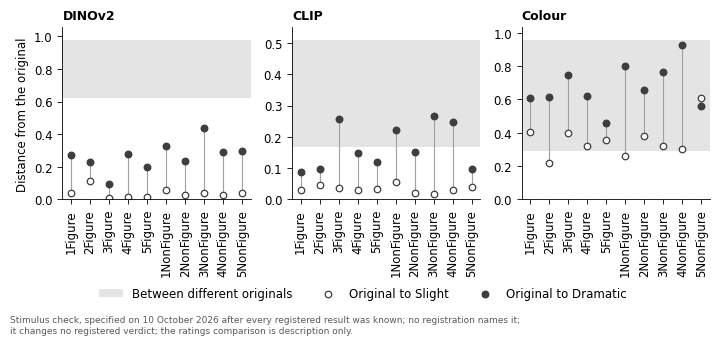

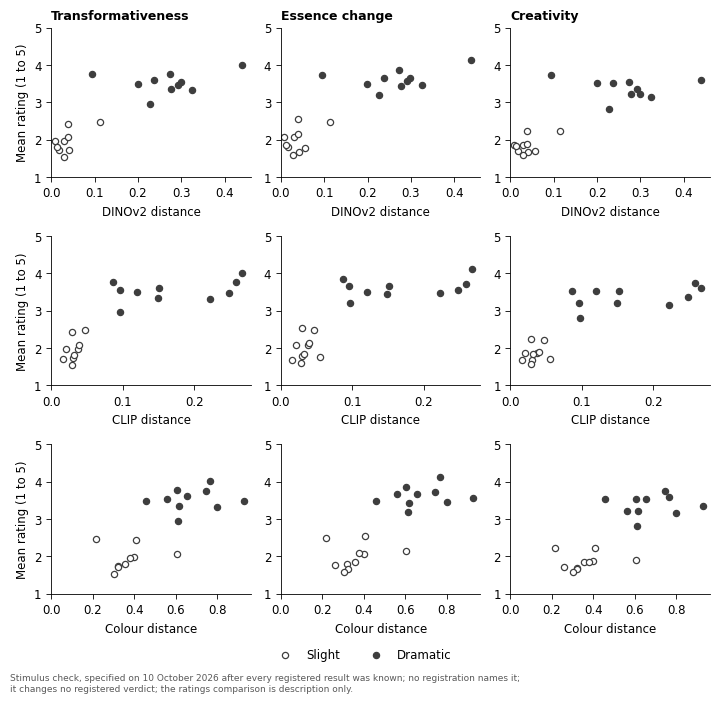

In [16]:
GREY_DARK, GREY_LIGHT, BAND = "#3E3E3E", "#A1A1A1", "#E4E4E4"
FOOT = ("Stimulus check, specified on 10 October 2026 after every registered result was known; no registration "
        "names it;\nit changes no registered verdict; the ratings comparison is description only.")
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "axes.edgecolor": "black", "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.color": "black", "ytick.color": "black", "axes.titlesize": 9, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "pdf.fonttype": 42, "savefig.dpi": 300})
MEASURE_TITLES = {"DINOv2": "DINOv2", "CLIP": "CLIP", "colour": "Colour"}
MEASURE_AXIS = {"DINOv2": "DINOv2 distance", "CLIP": "CLIP distance", "colour": "Colour distance"}
QUESTION_TITLES = {"transformativeness": "Transformativeness", "essence_change": "Essence change",
                   "creativity": "Creativity"}


def save_figure(figure, stem):
    for extension, metadata in (("pdf", {"CreationDate": None}), ("png", {})):
        path = os.path.join(FIGURES_DIR, "%s.%s" % (stem, extension))
        if os.path.exists(path):
            os.remove(path)
        figure.savefig(path, metadata=metadata)
        record("outputs", path)


figure, axes = plt.subplots(1, 3, figsize=(7.2, 3.4))
x = np.arange(len(ARTWORKS))
for axis, (measure, preprocessing) in zip(axes, PRIMARY):
    part = check2[(check2["measure"] == measure) & (check2["preprocessing"] == preprocessing)].set_index(
        "artwork").reindex(ARTWORKS)
    between = check1[(check1["measure"] == measure) & (check1["preprocessing"] == preprocessing)].iloc[0]
    axis.axhspan(between["smallest_between_originals"], between["largest_between_originals"], color=BAND,
                 zorder=0, lw=0, label="Between different originals")
    axis.vlines(x, part["slight_distance"], part["dramatic_distance"], color=GREY_LIGHT, lw=0.8, zorder=1)
    axis.scatter(x, part["slight_distance"], s=22, facecolor="white", edgecolor=GREY_DARK, lw=0.9, zorder=2,
                 label="Original to Slight")
    axis.scatter(x, part["dramatic_distance"], s=22, color=GREY_DARK, zorder=3, label="Original to Dramatic")
    axis.set_xticks(x, ARTWORKS, rotation=90)
    axis.set_ylim(0, max(between["largest_between_originals"], part["dramatic_distance"].max()) * 1.08)
    axis.set_title(MEASURE_TITLES[measure])
axes[0].set_ylabel("Distance from the original")
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.075))
figure.text(0.01, 0.01, FOOT, fontsize=6.5, color="0.35")
figure.tight_layout(rect=(0, 0.14, 1, 1))
save_figure(figure, "image_check_fig1_distances")
plt.show()

figure, axes = plt.subplots(3, 3, figsize=(7.2, 7.0))
everyone = by_image[(by_image["arm"] == "all participants") & (by_image["level"] != "None")]
for i, (measure, preprocessing) in enumerate(PRIMARY):
    column = "distance_%s_%s" % (measure, preprocessing.replace(" ", "_"))
    for j, question in enumerate(QUESTIONS):
        axis = axes[i, j]
        for level, face in (("Slight", "white"), ("Dramatic", GREY_DARK)):
            part = everyone[everyone["level"] == level]
            axis.scatter(part[column], part["mean_%s" % question], s=20, facecolor=face, edgecolor=GREY_DARK,
                         lw=0.9, label=level)
        axis.set_ylim(1, 5)
        axis.set_xlim(0, None)
        axis.set_xlabel(MEASURE_AXIS[measure])
        if i == 0:
            axis.set_title(QUESTION_TITLES[question])
        if j == 0:
            axis.set_ylabel("Mean rating (1 to 5)")
handles, labels = axes[0, 0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.035))
figure.text(0.01, 0.008, FOOT, fontsize=6.5, color="0.35")
figure.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(figure, "image_check_fig2_ratings")
plt.show()

---

# 9. Models, versions and the run manifest

`image_check_input_checks.csv` lists every check the run made, with the expected and observed value. `image_check_models.csv` records each network's repository, pinned revision, weight file, size and checksum, embedding size, both preprocessings, the device and number format of its weights as observed, and the number of images for which its standard crop equals the whole-image input, with a row for the colour measure. `image_check_package_versions.csv` records the Python and package versions of this run beside those in `requirements.txt`, with the thread count, the deterministic setting, and the device and number format of the networks' weights as observed on the loaded networks. The run manifest, written last, lists every input, every model file read and every output with its size and SHA-256 checksum; it is the one table that records a time.

In [17]:
write_table(pd.DataFrame(CHECKS), "image_check_input_checks.csv")
write_table(models_table, "image_check_models.csv")

version_rows = [dict(package="python", version=platform.python_version(), required="3.12",
                     matches=sys.version_info[:2] == (3, 12))]
version_rows += [dict(package=p, version=installed[p], required=pinned[p],
                      matches=release(installed[p]) == pinned[p]) for p in ANALYSIS_PACKAGES]
version_rows += [dict(package="torch threads", version=str(torch.get_num_threads()), required=str(THREADS),
                      matches=torch.get_num_threads() == THREADS),
                 dict(package="torch inter-op threads", version=str(torch.get_num_interop_threads()),
                      required=str(THREADS), matches=torch.get_num_interop_threads() == THREADS),
                 dict(package="torch deterministic algorithms", version=str(torch.are_deterministic_algorithms_enabled()),
                      required="True", matches=torch.are_deterministic_algorithms_enabled()),
                 dict(package="network weights device", version="; ".join(models_table["device"].iloc[:2]),
                      required="cpu; cpu", matches=list(models_table["device"].iloc[:2]) == ["cpu", "cpu"]),
                 dict(package="network weights dtype", version="; ".join(models_table["dtype"].iloc[:2]),
                      required="float32; float32",
                      matches=list(models_table["dtype"].iloc[:2]) == ["float32", "float32"])]
write_table(pd.DataFrame(version_rows), "image_check_package_versions.csv")

manifest_rows = []
completed = datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
for role, label in (("inputs", "input"), ("models", "model file"), ("outputs", "output")):
    for path in RUN[role]:
        manifest_rows.append(dict(role=label, file=show(path), bytes=os.path.getsize(path),
                                  sha256=sha256_file(path), completed_utc=completed))
run_manifest = pd.DataFrame(manifest_rows)
run_manifest["analysis_status"] = STATUS
run_manifest.to_csv(MANIFEST_PATH, index=False, lineterminator="\n")
print(run_manifest.groupby("role").size().to_string())
print("Run manifest written:", show(MANIFEST_PATH))

role
input         40
model file     6
output        14
Run manifest written: Analysis/R Analysis Pipeline/Cross-study/image_check/tables/image_check_run_manifest.csv
